In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from joblib import Parallel, delayed

# GLOBAL STYLE SETTINGS (run once)

plt.rcParams.update({

    # --- FONT SIZES ---
    "font.size": 24,              # base font size
    "axes.titlesize": 20,         # title
    "axes.labelsize": 36,         # x/y labels
    "xtick.labelsize": 36,
    "ytick.labelsize": 36,
    "legend.fontsize": 16,

    # --- LINES ---
    "lines.linewidth": 5,
    "lines.markersize": 16,

    # --- FIGURE / AXIS ---
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "axes.linewidth": 1.5,        # thicker axis spines

    # --- TICKS ---
    "xtick.major.size": 15,
    "xtick.major.width": 3,
    "ytick.major.size": 15,
    "ytick.major.width": 3,

    # --- LEGEND ---
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "legend.fancybox": True,

    # --- GRID (optional) ---
    #"axes.grid": True,
    #"grid.alpha": 0.3,
})


# I - Just look at the growth rates

## (1) Length L=1

In [2]:
import numpy as np
from scipy.linalg import expm, eigvals

def growth(Q, tau, nu, r_plus, r_minus, dt, PopSize=10**4, steps=None):
    Pop_t=np.zeros((steps,Q,2), dtype=int)
    if steps is None:
        steps = int(Q * tau / dt * 10)

    # environment
    H = np.array([1] + [0]*(Q-1))
    indices = np.concatenate((np.arange(1, Q), [0]))

    # population Pop[VR, DGR]
    Pop = np.zeros((Q,2), dtype=int)
    Pop[:,1] = np.random.multinomial(PopSize, [1/Q]*Q)  # start inactive

    AvH = [np.sum(Pop.sum(axis=1) * H) / PopSize]

    Kswitch = int(tau/dt)

    for k in range(1, steps+1):

        # ---- environmental switch ----
        if k > Kswitch:
            H = H[indices]
            Kswitch += int(tau/dt)

        # ---- selection ----
        weighted = Pop * np.exp(H*dt)[:,None]
        Proba = weighted / (np.sum(weighted) + 1e-16)

        Pop = np.random.multinomial(PopSize, Proba.reshape(-1)).reshape(Q,2)

        # ---- DGR switching ----
        off_to_on = np.random.binomial(Pop[:,0], r_plus*dt)
        on_to_off = np.random.binomial(Pop[:,1], r_minus*dt)

        Pop[:,0] += on_to_off - off_to_on
        Pop[:,1] += off_to_on - on_to_off

        # ---- VR replacement (only if DGR active) ----
        switch_out = np.random.binomial(Pop[:,1], nu*dt)
        Pop[:,1] -= switch_out

        redistributed = np.random.multinomial(np.sum(switch_out), [1/Q]*Q)
        Pop[:,1] += redistributed

        AvH.append(np.sum(Pop.sum(axis=1) * H) / PopSize)
        Pop_t[k-1,:,:]=Pop[:]
    return np.mean(AvH[int(steps//2):])

In [3]:
Q = 4
Hvec = np.array([1.0] + [0.0]*(Q-1))

# === Model functions ===

def A_matrix(Hvec, mu, Q):
    """
    Continuous dynamics matrix, equivalent to Mathematica A[Hvec, mu, Q]
    """
    mat = np.full((Q, Q), mu/Q)
    np.fill_diagonal(mat, Hvec - mu*(Q-1)/Q)
    return mat

def Mcycle(Hvec, mu, Q, tau):
    """
    Full-cycle matrix over Q successive tau-intervals (Mathematica Mcycle)
    """
    matrices = []
    Hlist = [np.roll(Hvec, k) for k in range(Q)]  # Rotate Hvec
    for H in Hlist:
        matrices.append(expm(A_matrix(H, mu, Q)*tau))
    # Multiply in temporal order (last first)
    result = matrices[-1]
    for mat in matrices[-2::-1]:
        result = result @ mat
    return result

def rInf(Hvec, mu, Q, tau):
    """
    Asymptotic effective growth rate, equivalent to Mathematica rInf
    """
    mat = Mcycle(Hvec, mu, Q, tau)
    rho = max(np.abs(eigvals(mat)))
    return np.log(rho)/(Q*tau)

In [4]:
from joblib import Parallel, delayed


def growth_for_nu_list( 
    Q, tau, nu_list, r_plus, r_minus, dt, PopSize=10**4, steps=None,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(growth)(Q, tau, nu, r_plus, r_minus, dt, PopSize, steps) for nu in nu_list
    )
    return results

1e-06
3.5475328760165508e-06
1.258498950641826e-05
4.464566401834217e-05
0.00015838196087665786
0.0005618652131779109
0.0019932353156386887
0.0070710678118654745
0.025084845531135186
0.08898931421149893
0.3156925177794593
1.1199295855350713
3.9729870235092632
14.094302081886251
49.99999999999999
1e-06
3.5475328760165508e-06
1.258498950641826e-05
4.464566401834217e-05
0.00015838196087665786
0.0005618652131779109
0.0019932353156386887
0.0070710678118654745
0.025084845531135186
0.08898931421149893
0.3156925177794593
1.1199295855350713
3.9729870235092632
14.094302081886251
49.99999999999999
1e-06
3.5475328760165508e-06
1.258498950641826e-05
4.464566401834217e-05
0.00015838196087665786
0.0005618652131779109
0.0019932353156386887
0.0070710678118654745
0.025084845531135186
0.08898931421149893
0.3156925177794593
1.1199295855350713
3.9729870235092632
14.094302081886251
49.99999999999999


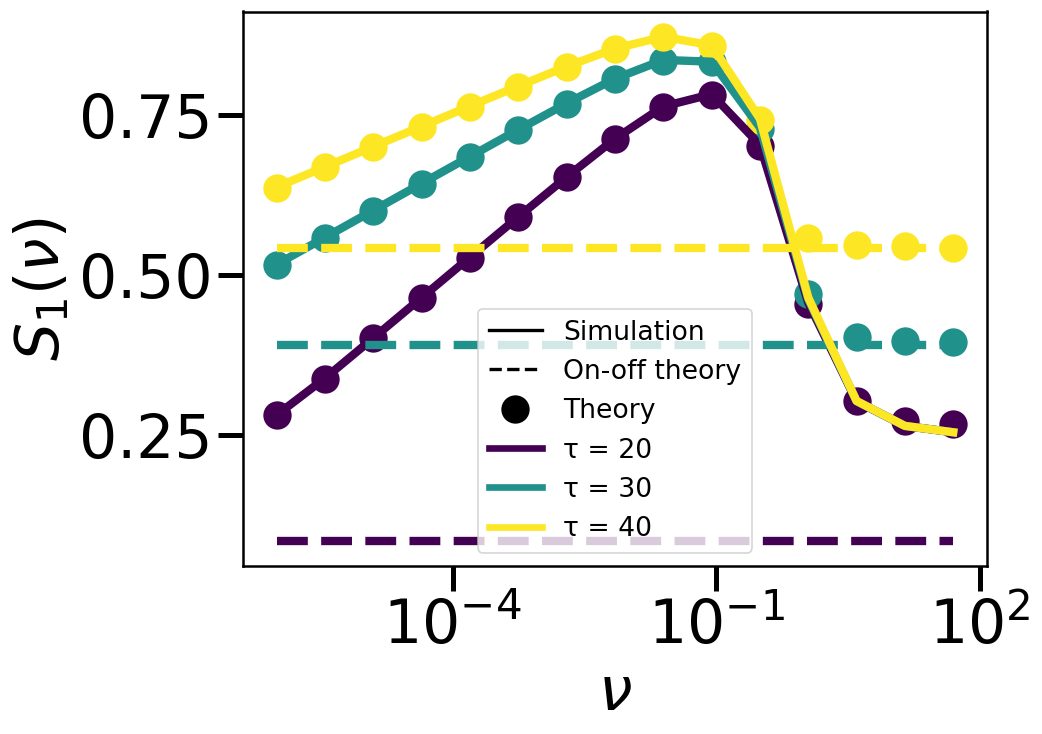

In [5]:
dt=0.01
r_plus=1e-5
r_minus=1e-3
Q=4 
L=1

nu_lis=np.logspace(-6,np.log10(50),15)
tau_lis=[20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0
for tau in tau_lis:
    S=[]
    S_theo=[]
    S_approx=[]
    S=growth_for_nu_list(Q, tau, nu_lis, r_plus, r_minus, dt, PopSize=10**12,steps=int(10*tau/dt))
    for nu in nu_lis:
        print(nu)
        
        S_theo.append(rInf(Hvec, nu, Q, tau))
    plt.scatter(nu_lis,S,color=colors[k])
    plt.plot(nu_lis,[L+np.log((2+1/(1-1/Q))*r_plus*r_minus/(1-1/Q)/Q**L/L**2)/tau]*len(nu_lis),'--',color=colors[k])
    plt.plot(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], linestyle='--',color='k', lw=2, label='On-off theory'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') 
               for color, tau in zip(colors, tau_lis)]

plt.legend(handles=legend_lines + tau_handles)

plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_1(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_on_off_L=1.svg')

## Length L=2

In [6]:
def compete_4x4_onoff(
    tau, nu, r_plus, r_minus, dt,
    PopSize=10**8,
    steps=1000
):


    # --- Helper: TR/VR pairs ---
    pairs = [(i, j) for i in range(4) for j in range(4)]  # 16 pairs

    # --- Initialize population: evenly across TR×VR, all DGR=off ---
    Pop = np.zeros(( 16, 2), dtype=np.int64)
    base_each = PopSize // ( 16 * 2)
    if base_each > 0:
        Pop[:, 0] = base_each  # All start with DGR off
    leftover = PopSize - Pop.sum()
    if leftover > 0:
        Pop[ 0, 0] += leftover  # Give leftover to (TR=0, VR=0, DGR=0)

    # --- Environment cycle ---
    env_cycle = [(0,0), (1,1), (2,2), (3,3)]
    Hcycle = []
    for (E1, E2) in env_cycle:
        h = np.zeros(16)
        for idx, (x, y) in enumerate(pairs):
            h[idx] =  (1 if x == E1 else 0) + (1 if y == E2 else 0)
        Hcycle.append(h)
    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    AvH = []

    for k in range(steps):
        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        w = np.exp(H * dt)  # Fitness per VR (16,)
        weighted = Pop * w[None, :, None]  # Broadcast to (16,16,2)
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones((16, 2)) / ( 16 * 2)
        else:
            P_repro = weighted / total_fit

        new_counts = np.random.multinomial(PopSize, P_repro.reshape(-1))
        Pop = new_counts.reshape( 16, 2)

        # ---- DGR SWITCHING (on/off) ----
        # Off → On
        off_to_on = np.random.binomial(Pop[ :, 0], r_plus * dt)
        Pop[ :, 0] -= off_to_on
        Pop[ :, 1] += off_to_on

        # On → Off
        on_to_off = np.random.binomial(Pop[ :, 1], r_minus * dt)
        Pop[ :, 1] -= on_to_off
        Pop[ :, 0] += on_to_off

        # ---- VR SWITCHING (only for DGR=on) ----
        if nu * dt > 0:
                for vr in range(16):
                    count = Pop[ vr, 1]  # Only DGR=on
                    if count == 0:
                        continue
                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue
                    Pop[ vr, 1] -= s
                    Pop[ :, 1] += np.random.multinomial(s, [1/16.0] * 16)

        # ---- Statistics ----
        AvH.append(np.sum(Pop * H[None, :, None]) / PopSize)

    # Discard initial transient (3 environment periods)
    cut = 3 * int(tau / dt)
    return np.mean(AvH[cut:])

20
0.0001
0.00042975297258771337
0.0018468761744797571
0.007937005259840991
0.03410951603860982
0.14658665911120855
0.6299605249474363
2.7072740820907684
11.634590843881808
49.99999999999999
30
0.0001
0.00042975297258771337
0.0018468761744797571
0.007937005259840991
0.03410951603860982
0.14658665911120855
0.6299605249474363
2.7072740820907684
11.634590843881808
49.99999999999999
40
0.0001
0.00042975297258771337
0.0018468761744797571
0.007937005259840991
0.03410951603860982
0.14658665911120855
0.6299605249474363
2.7072740820907684
11.634590843881808
49.99999999999999


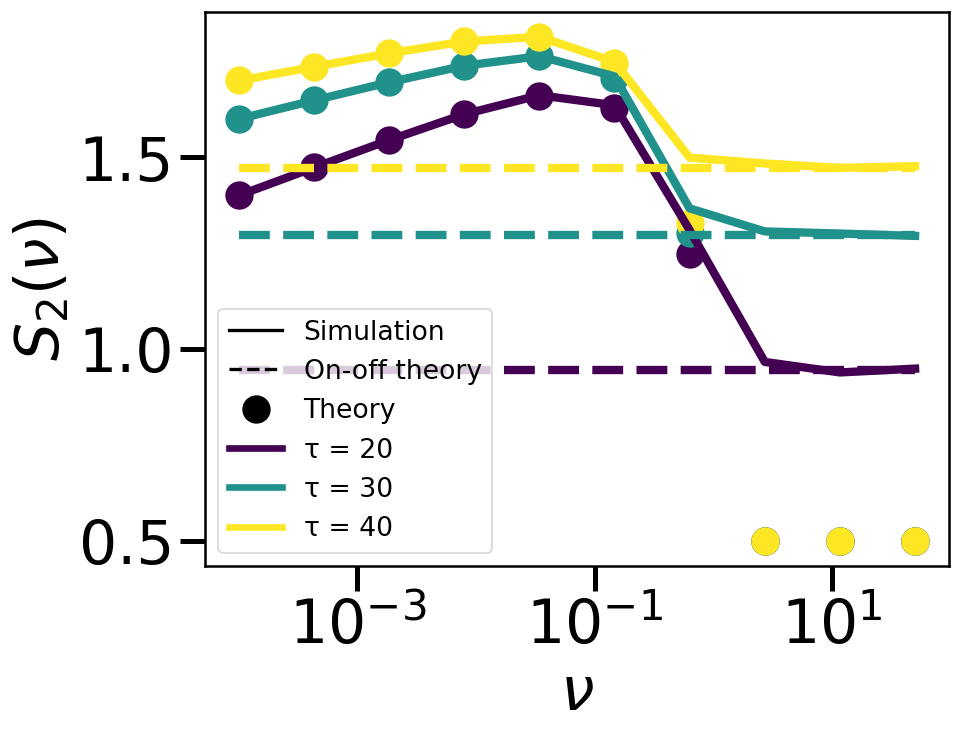

In [7]:

dt=0.01
r_plus=1e-5
r_minus=1e-3
L=2


nu_lis=np.logspace(-4,np.log10(50),10)
tau_lis=[20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0




def growth_for_nu_list( 
    tau, nu_list, r_plus, r_minus, dt,
        PopSize=10**12,
        steps=40000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_4x4_onoff)(tau, nu, r_plus, r_minus, dt,
        PopSize,
        steps) for nu in nu_list
    )
    return results

for tau in tau_lis:
    print(tau)
    S=growth_for_nu_list(tau, nu_lis, r_plus, r_minus, dt,
        PopSize=10**12,
        steps=int(tau/dt*10))
    S_theo=[]
    
    for nu in nu_lis:
        print(nu)
        S_theo.append(max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau))
    plt.plot(nu_lis,S,color=colors[k])
    plt.plot(nu_lis,len(nu_lis)*[L+np.log((2+1/(1-1/Q))*r_plus*r_minus/(1-1/Q)/Q**L/L**2)/tau],'--',color=colors[k])
    plt.scatter(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], linestyle='--',color='k', lw=2, label='On-off theory'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') for color, tau in zip(colors, tau_lis)]


plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_2(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_on_off_L=2.svg')

## L=4

In [8]:
def compete_256_onoff(
    tau, nu, r_plus, r_minus, dt,
    PopSize=10**8,
    steps=1000
):


    # --- Helper: TR/VR pairs ---
    pairs = [(i, j,k,l) for i in range(4) for j in range(4) for k in range(4) for l in range(4)]  # 16 pairs

    # --- Initialize population: evenly across TR×VR, all DGR=off ---
    Pop = np.zeros(( 256, 2), dtype=np.int64)
    base_each = PopSize // ( 256 * 2)
    if base_each > 0:
        Pop[:, 0] = base_each  # All start with DGR off
    leftover = PopSize - Pop.sum()
    if leftover > 0:
        Pop[ 0, 0] += leftover  # Give leftover to (TR=0, VR=0, DGR=0)

    # --- Environment cycle ---
    env_cycle = [(0,0,0,0), (1,1,1,1), (2,2,2,2), (3,3,3,3)]
    Hcycle = []
    for (E1, E2,E3,E4) in env_cycle:
        h = np.zeros(256)
        for idx, (x, y,z,a) in enumerate(pairs):
            h[idx] =  (1 if x == E1 else 0) + (1 if y == E2 else 0) + (1 if z == E3 else 0) + (1 if a == E4 else 0)
        Hcycle.append(h)
    n_env = len(Hcycle)
    Hindex = 0
    H = Hcycle[Hindex]
    next_switch = tau / dt

    AvH = []

    for k in range(steps):
        # ---- Environment switch ----
        if k > next_switch:
            Hindex = (Hindex + 1) % n_env
            H = Hcycle[Hindex]
            next_switch += tau / dt

        # ---- SELECTION / REPRODUCTION ----
        w = np.exp(H * dt)  # Fitness per VR (16,)
        weighted = Pop * w[None, :, None]  # Broadcast to (16,16,2)
        total_fit = weighted.sum()
        if total_fit <= 0:
            P_repro = np.ones((256, 2)) / ( 256 * 2)
        else:
            P_repro = weighted / total_fit

        new_counts = np.random.multinomial(PopSize, P_repro.reshape(-1))
        Pop = new_counts.reshape( 256, 2)

        # ---- DGR SWITCHING (on/off) ----
        # Off → On
        off_to_on = np.random.binomial(Pop[ :, 0], r_plus * dt)
        Pop[ :, 0] -= off_to_on
        Pop[ :, 1] += off_to_on

        # On → Off
        on_to_off = np.random.binomial(Pop[ :, 1], r_minus * dt)
        Pop[ :, 1] -= on_to_off
        Pop[ :, 0] += on_to_off

        # ---- VR SWITCHING (only for DGR=on) ----
        if nu * dt > 0:
                for vr in range(256):
                    count = Pop[ vr, 1]  # Only DGR=on
                    if count == 0:
                        continue
                    s = np.random.binomial(count, nu * dt)
                    if s == 0:
                        continue
                    Pop[ vr, 1] -= s
                    Pop[ :, 1] += np.random.multinomial(s, [1/256.0] * 256)

        # ---- Statistics ----
        AvH.append(np.sum(Pop * H[None, :, None]) / PopSize)

    # Discard initial transient (3 environment periods)
    cut = 3 * int(tau / dt)
    return np.mean(AvH[cut:])

20
0.0001
0.00035938136638046257
0.001291549665014884
0.004641588833612782
0.016681005372000592
0.05994842503189409
0.21544346900318845
0.7742636826811278
2.782559402207126
10.0
30
0.0001
0.00035938136638046257
0.001291549665014884
0.004641588833612782
0.016681005372000592
0.05994842503189409
0.21544346900318845
0.7742636826811278
2.782559402207126
10.0
40
0.0001
0.00035938136638046257
0.001291549665014884
0.004641588833612782
0.016681005372000592
0.05994842503189409
0.21544346900318845
0.7742636826811278
2.782559402207126
10.0


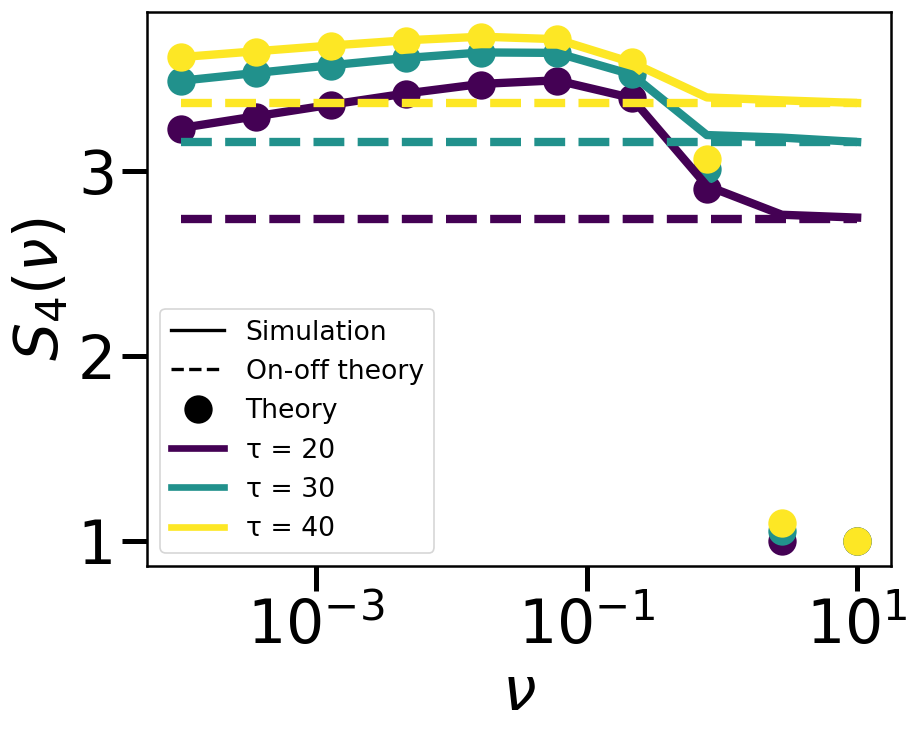

In [9]:

dt=0.05
r_plus=1e-5
r_minus=1e-3
L=4


nu_lis=np.logspace(-4,np.log10(10),10)
tau_lis=[20,30,40]
colors = plt.cm.viridis(np.linspace(0, 1, len(tau_lis)))
k=0




def growth_for_nu_list( 
    tau, nu_list, r_plus, r_minus, dt,
        PopSize=10**12,
        steps=40000,
    n_jobs=-1):
    results = Parallel(n_jobs=n_jobs)(
        delayed(compete_256_onoff)(tau, nu, r_plus, r_minus, dt,
        PopSize,
        steps) for nu in nu_list
    )
    return results

for tau in tau_lis:
    print(tau)
    S=growth_for_nu_list(tau, nu_lis, r_plus, r_minus, dt,
        PopSize=10**12,
        steps=int(tau/dt*10))
    S_theo=[]
    
    for nu in nu_lis:
        print(nu)
        S_theo.append(max(L/Q,L-nu*(1-Q**(-L))+np.log(2*nu/Q**L/L)/tau))
    plt.plot(nu_lis,S,color=colors[k])
    plt.plot(nu_lis,len(nu_lis)*[L+np.log((2+1/(1-1/Q))*r_plus*r_minus/(1-1/Q)/Q**L/L**2)/tau],'--',color=colors[k])
    plt.scatter(nu_lis,S_theo,label=f'τ = {tau}',color=colors[k])
    k+=1
# --- Custom legend ---
legend_lines = [Line2D([0], [0], color='k', lw=2, label='Simulation'),
                Line2D([0], [0], linestyle='--',color='k', lw=2, label='On-off theory'),
                Line2D([0], [0], marker='o', color='w', markerfacecolor='k',
                       markeredgecolor='k', label='Theory')]

tau_handles = [Line2D([0], [0], color=color, lw=4, label=f'τ = {tau}') for color, tau in zip(colors, tau_lis)]


plt.xlabel(r"$\nu$")
plt.ylabel(r"$S_4(\nu)$")
plt.semilogx()
plt.legend(handles=legend_lines + tau_handles)
plt.savefig('Effective_Growth_VR_on_off_L=4.svg')